### Startup Acquisition Prediction - EDA

#### Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

In [2]:
full_df = pd.read_csv("data/startup_success_raw.csv")

df = full_df.sample(frac = 0.5, random_state=42)

df

,funding_rounds,founder_experience_years,team_size,market_size_billion,product_traction_users,burn_rate_million,revenue_million,investor_type,sector,founder_background,outcome
75721,0,17,75,8.366118,233733,14.491444,3.491873e+05,tier2_vc,SaaS,serial_founder,Failure
80184,1,13,28,2.934475,133877,6.734171,2.884233e+05,angel,Ecommerce,serial_founder,Failure
19864,2,22,171,46.991055,306468,27.949743,1.390226e+06,angel,Crypto,serial_founder,Acquisition
76699,2,13,217,102.002796,370579,25.669631,9.360390e+05,none,Climate,first_time,Failure
92991,1,14,182,21.455660,141806,28.685077,7.046956e+05,angel,Fintech,first_time,Acquisition
...,...,...,...,...,...,...,...,...,...,...,...
33072,3,7,166,6.935243,81481,16.161065,2.028450e+05,none,Health,first_time,Failure
95599,2,9,56,4.350784,291046,37.582971,5.328968e+05,none,SaaS,ex_bigtech,Failure
28006,0,5,227,7.374647,282677,30.249674,7.220005e+05,angel,Fintech,serial_founder,Acquisition
90487,3,24,166,83.575310,140582,10.869093,2.602291e+05,tier2_vc,Crypto,serial_founder,Failure


In [3]:
df.dtypes

funding_rounds                int64
founder_experience_years      int64
team_size                     int64
market_size_billion         float64
product_traction_users        int64
burn_rate_million           float64
revenue_million             float64
investor_type                   str
sector                          str
founder_background              str
outcome                         str
dtype: object

In [4]:
df.describe()

,funding_rounds,founder_experience_years,team_size,market_size_billion,product_traction_users,burn_rate_million,revenue_million
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,5.000000e+04
mean,2.004960,12.043760,150.580940,33.218094,285285.20160,16.775028,7.805274e+05
std,1.416833,7.213685,86.165073,43.162125,158865.59417,15.533334,6.036074e+05
min,0.000000,0.000000,2.000000,0.375376,668.00000,0.279763,1.344810e+03
25%,1.000000,6.000000,76.000000,10.289885,161683.75000,7.087502,3.155188e+05
50%,2.000000,12.000000,151.000000,20.130650,264979.00000,12.181289,6.238784e+05
75%,3.000000,18.000000,225.000000,39.510509,389068.50000,21.018872,1.095982e+06
max,8.000000,24.000000,299.000000,1072.434476,915203.00000,313.639830,4.168443e+06


In [5]:
df.isna().sum()

funding_rounds              0
founder_experience_years    0
team_size                   0
market_size_billion         0
product_traction_users      0
burn_rate_million           0
revenue_million             0
investor_type               0
sector                      0
founder_background          0
outcome                     0
dtype: int64

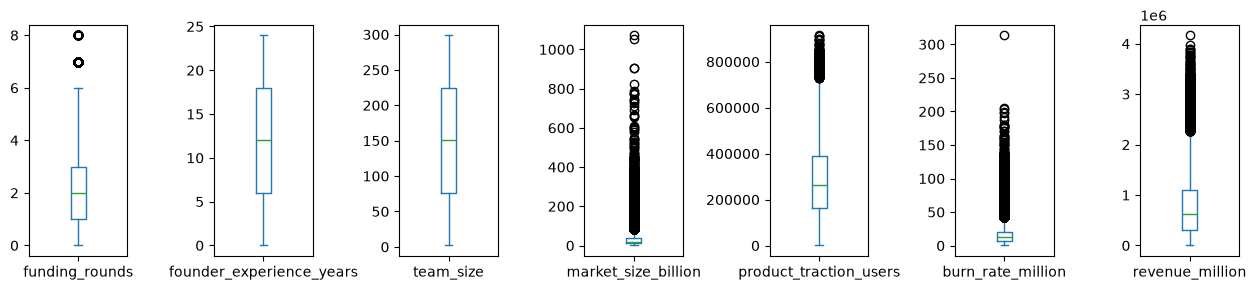

In [6]:
df.plot(kind="box",subplots=True,layout=(1,11),figsize=(20,3))
plt.tight_layout()

In [30]:
outlier_columns = ['funding_rounds','market_size_billion','product_traction_users','burn_rate_million','revenue_million']

for col in outlier_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    minimum = q1 - (1.5 * iqr)
    maximum = q3 + (1.5 * iqr)
    df = df[(df[col] >= minimum) & (df[col] <= maximum)]

df

,funding_rounds,founder_experience_years,team_size,market_size_billion,product_traction_users,burn_rate_million,revenue_million,investor_type,sector,founder_background,outcome
75721,0,17,75,8.366118,233733,14.491444,3.491873e+05,tier2_vc,SaaS,serial_founder,Failure
80184,1,13,28,2.934475,133877,6.734171,2.884233e+05,angel,Ecommerce,serial_founder,Failure
19864,2,22,171,46.991055,306468,27.949743,1.390226e+06,angel,Crypto,serial_founder,Acquisition
92991,1,14,182,21.455660,141806,28.685077,7.046956e+05,angel,Fintech,first_time,Acquisition
84004,2,4,159,25.335421,445781,21.894905,1.079444e+06,none,Ecommerce,first_time,Acquisition
...,...,...,...,...,...,...,...,...,...,...,...
52247,3,5,147,25.484140,281470,7.943478,4.045223e+05,tier1_vc,SaaS,serial_founder,Failure
54755,3,23,125,11.431414,63944,16.782599,2.185988e+05,tier2_vc,Ecommerce,first_time,Failure
33072,3,7,166,6.935243,81481,16.161065,2.028450e+05,none,Health,first_time,Failure
28006,0,5,227,7.374647,282677,30.249674,7.220005e+05,angel,Fintech,serial_founder,Acquisition


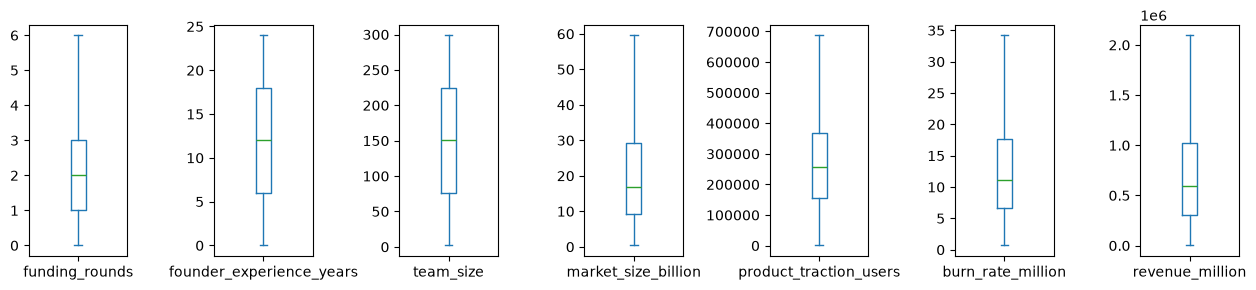

In [31]:
df.plot(kind="box",subplots=True,layout=(1,11),figsize=(20,3))
plt.tight_layout()

In [32]:
categorical_columns = [col for col in df.columns if df[col].dtypes == 'str']

categorical_columns

['investor_type', 'sector', 'founder_background', 'outcome']

In [33]:
for col in categorical_columns:
    df[col] = df[col].astype('category')

df.dtypes

funding_rounds                 int64
founder_experience_years       int64
team_size                      int64
market_size_billion          float64
product_traction_users         int64
burn_rate_million            float64
revenue_million              float64
investor_type               category
sector                      category
founder_background          category
outcome                     category
dtype: object

In [34]:
encoder = LabelEncoder()

for col in categorical_columns:
    df[col] = encoder.fit_transform(df[col])

df

,funding_rounds,founder_experience_years,team_size,market_size_billion,product_traction_users,burn_rate_million,revenue_million,investor_type,sector,founder_background,outcome
75721,0,17,75,8.366118,233733,14.491444,3.491873e+05,3,6,3,1
80184,1,13,28,2.934475,133877,6.734171,2.884233e+05,0,3,3,1
19864,2,22,171,46.991055,306468,27.949743,1.390226e+06,0,2,3,0
92991,1,14,182,21.455660,141806,28.685077,7.046956e+05,0,4,2,0
84004,2,4,159,25.335421,445781,21.894905,1.079444e+06,1,3,2,0
...,...,...,...,...,...,...,...,...,...,...,...
52247,3,5,147,25.484140,281470,7.943478,4.045223e+05,2,6,3,1
54755,3,23,125,11.431414,63944,16.782599,2.185988e+05,3,3,2,1
33072,3,7,166,6.935243,81481,16.161065,2.028450e+05,1,5,2,1
28006,0,5,227,7.374647,282677,30.249674,7.220005e+05,0,4,3,0


In [38]:
for col in categorical_columns:
    print(df[col].unique())

[3 0 1 2]
[6 3 2 4 0 5 1]
[3 2 1 0]
[1 0 2]


In [ ]:
df.to_csv